# **Cell 1 - Mount Google Drive**

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

Mounted at /content/drive


# **Cell 2 - Path Proyek**

In [ ]:
ROOT = Path("/content/drive/MyDrive/Detection Object - Yolo8")

print("Folder ada:", ROOT.exists())
print(*list(ROOT.iterdir()), sep="\n")

Folder ada: True
/content/drive/MyDrive/Detection Object - Yolo8/README.roboflow.txt
/content/drive/MyDrive/Detection Object - Yolo8/test
/content/drive/MyDrive/Detection Object - Yolo8/Tang Rivet
/content/drive/MyDrive/Detection Object - Yolo8/Penggaris Siku 25 CM
/content/drive/MyDrive/Detection Object - Yolo8/notebooks
/content/drive/MyDrive/Detection Object - Yolo8/Water Pass
/content/drive/MyDrive/Detection Object - Yolo8/valid
/content/drive/MyDrive/Detection Object - Yolo8/app
/content/drive/MyDrive/Detection Object - Yolo8/train
/content/drive/MyDrive/Detection Object - Yolo8/Tekiro C Clamp
/content/drive/MyDrive/Detection Object - Yolo8/docs
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Kayu
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Besi
/content/drive/MyDrive/Detection Object - Yolo8/Meteran
/content/drive/MyDrive/Detection Object - Yolo8/Gunting
/content/drive/MyDrive/Detection Object - Yolo8/Gunting Plat
/content/drive/MyDrive/Detection Object - Yolo

# **Cell 3 - Cek dataset**

In [ ]:
for split in ["train", "valid", "test"]:
    n_img = len(list((ROOT / split / "images").glob("*.jpg")))
    n_lab = len(list((ROOT / split / "labels").glob("*.txt")))
    print(f"{split:6}  gambar={n_img:3}  label={n_lab:3}")

train   gambar= 40  label= 40
valid   gambar= 11  label= 11
test    gambar= 11  label= 11


# **Cell 4 - Perbaiki data.yaml**

In [ ]:
yaml_path = ROOT / "data.yaml"
yaml_path.write_text(f"""path: {ROOT}
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']
""")
print(yaml_path.read_text())

path: /content/drive/MyDrive/Detection Object - Yolo8
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']



# **Cell 5 - Install & cek GPU**

In [ ]:
%pip install ultralytics -q
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "MASIH CPU")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
PyTorch: 2.11.0+cu128
GPU: Tesla T4


# **Cell 6 - Train**

In [ ]:
model = YOLO("yolov8n.pt")
model.train(
    data=str(ROOT / "data.yaml"),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project=str(ROOT / "runs"),
    name="colab",
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Detection Object - Yolo8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=col

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dde78c64590>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

# **Cell 7- Cek hasil (setelah train selesai)**

best.pt: True


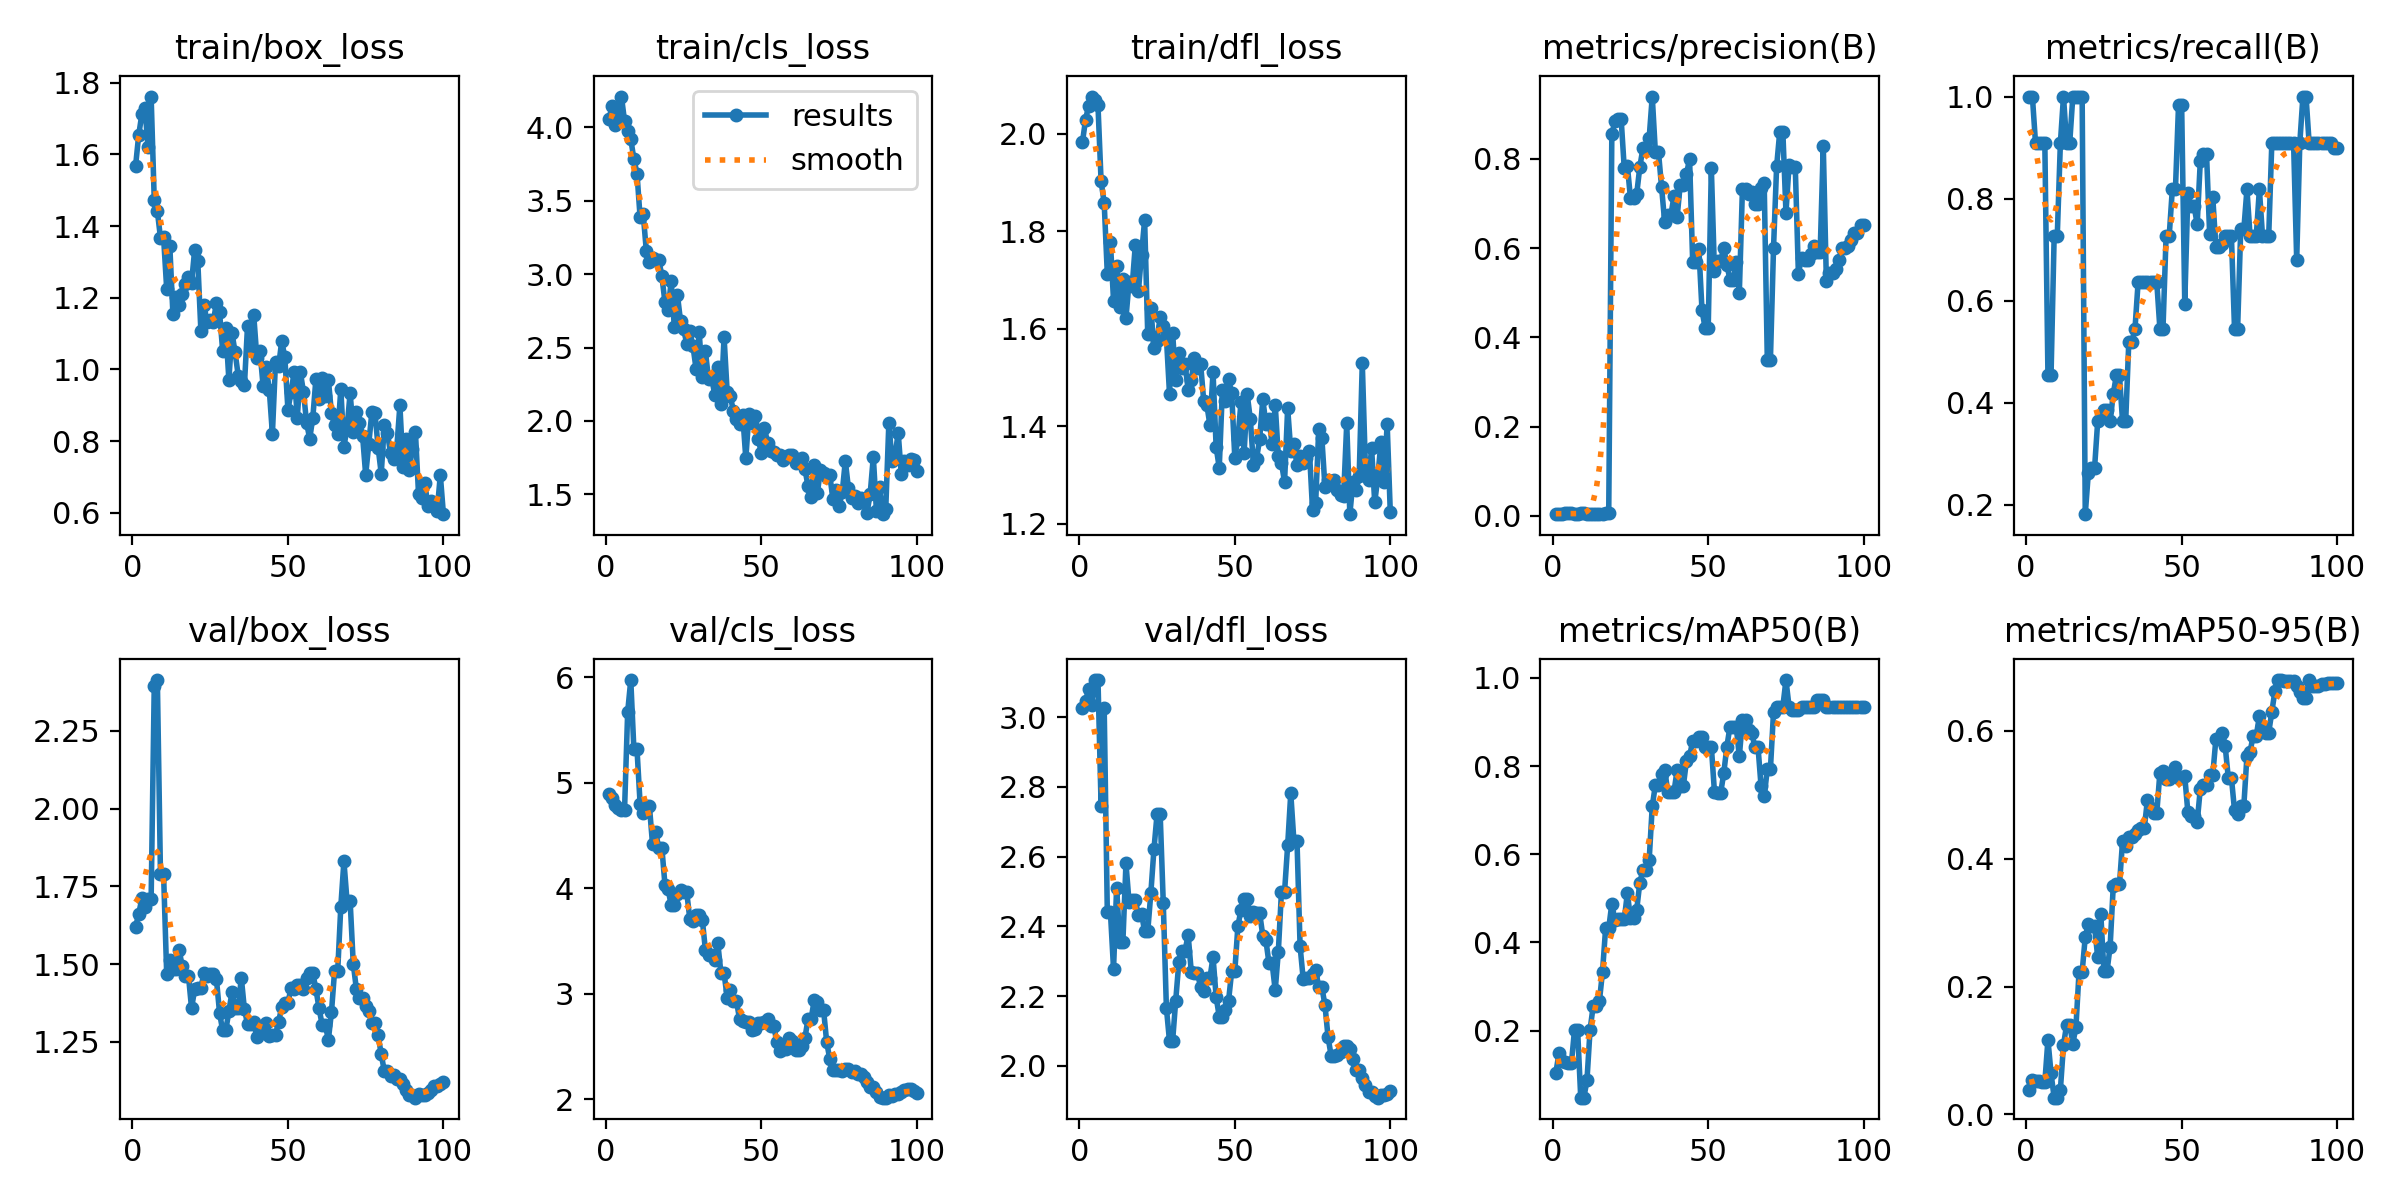

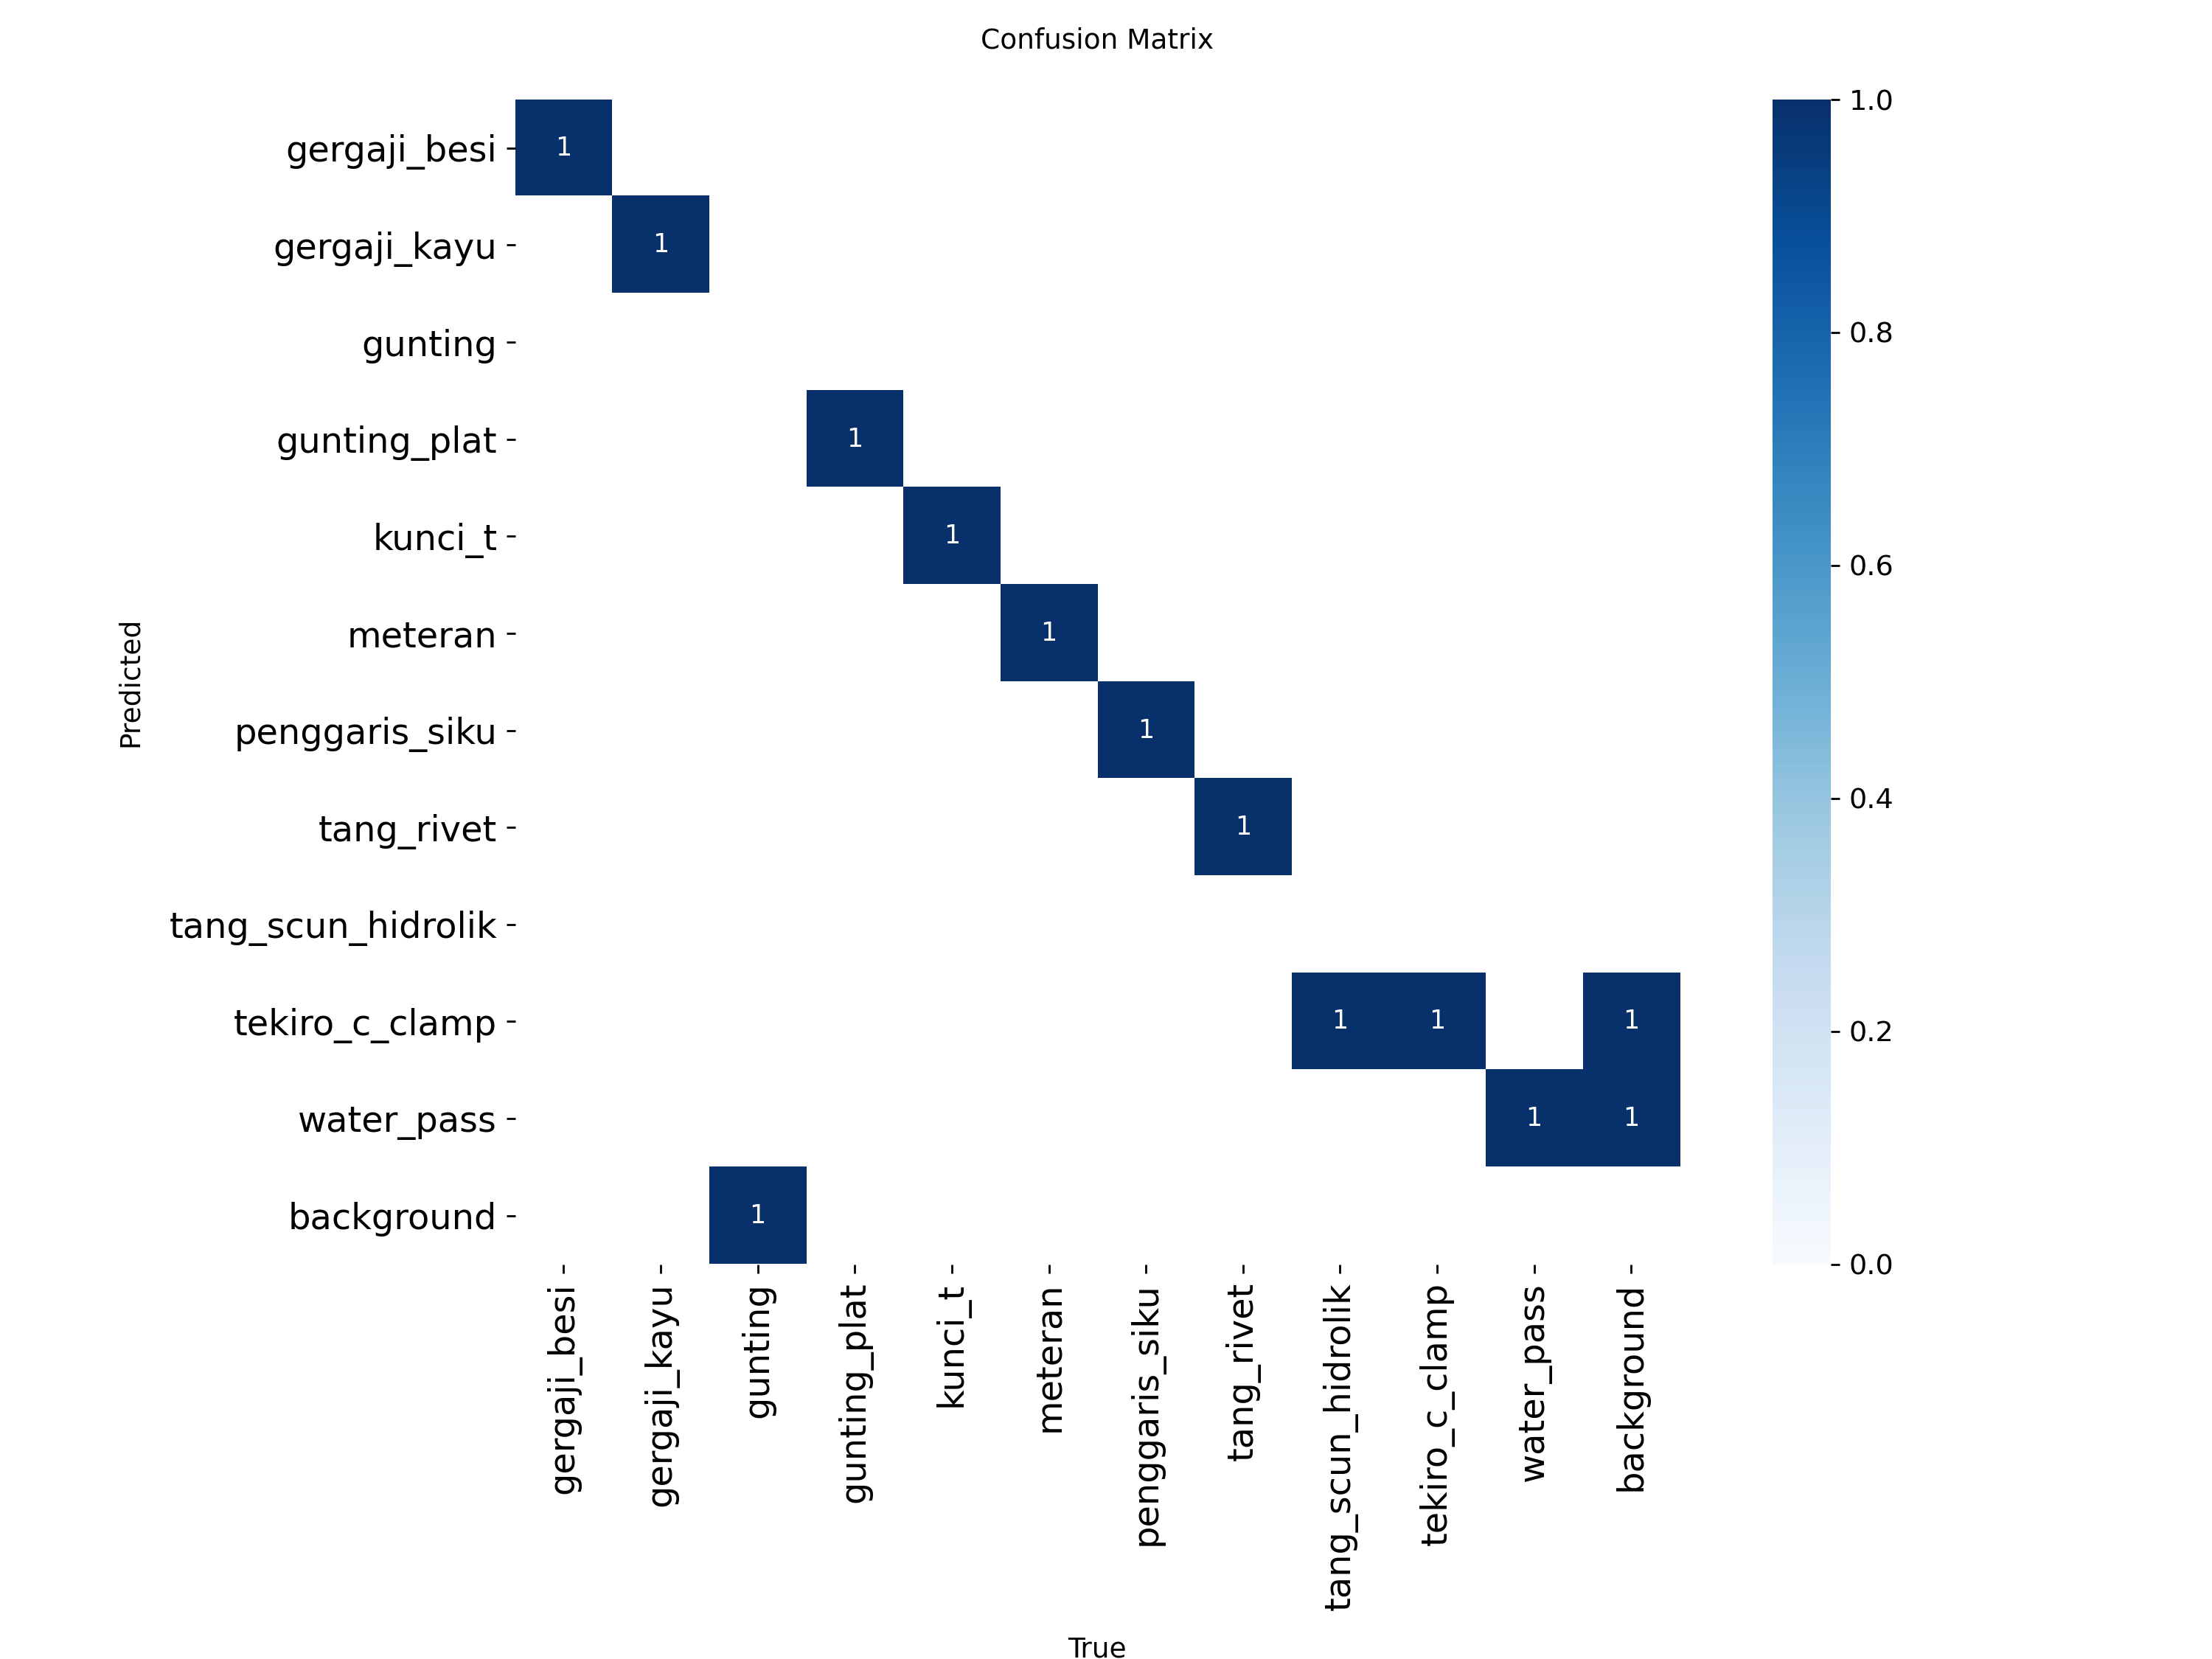

In [ ]:
from IPython.display import Image, display

run = ROOT / "runs" / "colab"
print("best.pt:", (run / "weights" / "best.pt").exists())

for f in ["results.png", "confusion_matrix.png"]:
    p = run / f
    if p.exists():
        display(Image(str(p)))

# **Cell 8 - Test 1 Folder Gambar**

In [ ]:
model = YOLO(str(ROOT / "runs" / "colab" / "weights" / "best.pt"))
model.predict(
    source=str(ROOT / "test" / "images"),
    save=True,
    conf=0.5,
    project=str(ROOT / "runs"),
    name="predict",
)
print("Hasil:", ROOT / "runs" / "predict")


image 1/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_09_57_39_Pro_jpg.rf.8a59aca4fc2ef4054c3890d681f971b3.jpg: 640x640 1 kunci_t, 7.3ms
image 2/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_10_03_32_Pro_jpg.rf.ec10ebc67e88848f6ef7caea5784f2c2.jpg: 640x640 1 tang_rivet, 26.3ms
image 3/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_10_06_11_Pro_jpg.rf.d1e0306c71b4f986b202161ab7c6ae12.jpg: 640x640 1 gergaji_besi, 1 gergaji_kayu, 49.0ms
image 4/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_10_07_35_Pro_jpg.rf.199dcdf82d53c269b7cf993060262c01.jpg: 640x640 1 gergaji_besi, 46.6ms
image 5/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_10_11_12_Pro_jpg.rf.bccd3bf088d410ccf6ae66627b515b16.jpg: 640x640 1 water_pass, 37.8ms
image 6/11 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20260821_10_13_12_Pro_jpg.rf.9412f7ca38d1910de636d5d1